# 04 - Error analysis, inference and the application  (RUN ON: DGX or your laptop)

Needs the trained runs and `results/final_model.json` (from notebook 03 / `scripts/compare.py`).
Covers: where the models fail, Grad-CAM, the inference pipeline, TFLite export, your own real-world photos, and launching the web app.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

In [2]:
# ===== SETUP - run this cell first =====
import os, subprocess, sys
from pathlib import Path

# Colab only: put your GitHub repo URL here, OR leave "" and upload + unzip the project zip to /content
REPO_URL = ""

IN_COLAB = "google.colab" in sys.modules
PROJECT_DIR = Path("/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone")
ZIP = Path("/content/fresh-rotten-fruit-capstone.zip")      # Colab: the project zip you uploaded to the Files panel
if not (PROJECT_DIR / "src").exists() and ZIP.exists():
    import shutil; shutil.unpack_archive(str(ZIP), "/content")
if not (PROJECT_DIR / "src").exists():
    if REPO_URL:
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    else:
        raise SystemExit(f"Project folder not found: {PROJECT_DIR}. Upload fresh-rotten-fruit-capstone.zip to /content (Files panel) or set REPO_URL above, then re-run.")
if IN_COLAB and os.getenv("FRUIT_SKIP_PIP") != "1":
    # Colab already has TensorFlow/pandas/scikit-learn; only the extras are installed (never reinstall TensorFlow).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_DIR / "requirements-colab.txt")], check=True)
sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)

from fruitfresh import config
print("Project:", PROJECT_DIR, "| split dir:", config.DEFAULT_SPLIT_DIR, "| work dir:", config.DEFAULT_WORK_DIR)

Project: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone | split dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/data/splits | work dir: /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/workspace


In [3]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from fruitfresh import error_analysis as EA
from fruitfresh.data_index import get_dataset_root
from fruitfresh.paths import resolve_model
from fruitfresh.train import run_dir_for

DATA_ROOT = get_dataset_root(); WORK_DIR = config.DEFAULT_WORK_DIR; RESULTS = config.DEFAULT_RESULTS_DIR; SEED = config.SEED
RUN = json.loads((RESULTS / "final_model.json").read_text())["final_model"]       # or set e.g. "baseline_cnn"
metrics = json.loads((run_dir_for(WORK_DIR, RUN, SEED) / "eval" / "metrics.json").read_text())
pred = pd.read_csv(run_dir_for(WORK_DIR, RUN, SEED) / "eval" / "predictions_test_original.csv")
print("run:", RUN, "| images:", len(pred))

I0000 00:00:1792934582.862338  191806 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792934582.934770  191806 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792934593.158501  191806 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


run: mobilenet_v2 | images: 215


## 1. Which mistakes happen?

In [4]:
display(EA.top_confusions(metrics["test_original"]["confusion_matrix"]))
print(EA.status_vs_fruit_errors(pred)); print(EA.confidence_summary(pred))

,true class,predicted as,count,share of true class
0,rottenoranges,rottenapples,3,0.120
1,freshoranges,freshapples,2,0.065
2,freshbanana,rottenbanana,2,0.080
3,rottenapples,freshapples,2,0.038
4,freshoranges,rottenoranges,2,0.065
5,rottenoranges,rottenbanana,2,0.080


{'n_errors': 14, 'freshness_mistakes (fresh<->rotten)': 7, 'fruit_type_mistakes': 7, 'freshness_accuracy': 0.9674418604651163, 'fruit_type_accuracy': 0.9674418604651163}
{'mean_confidence_correct': 0.9846441894527362, 'mean_confidence_wrong': 0.9191249, 'wrong_with_confidence_>=0.9': 9}


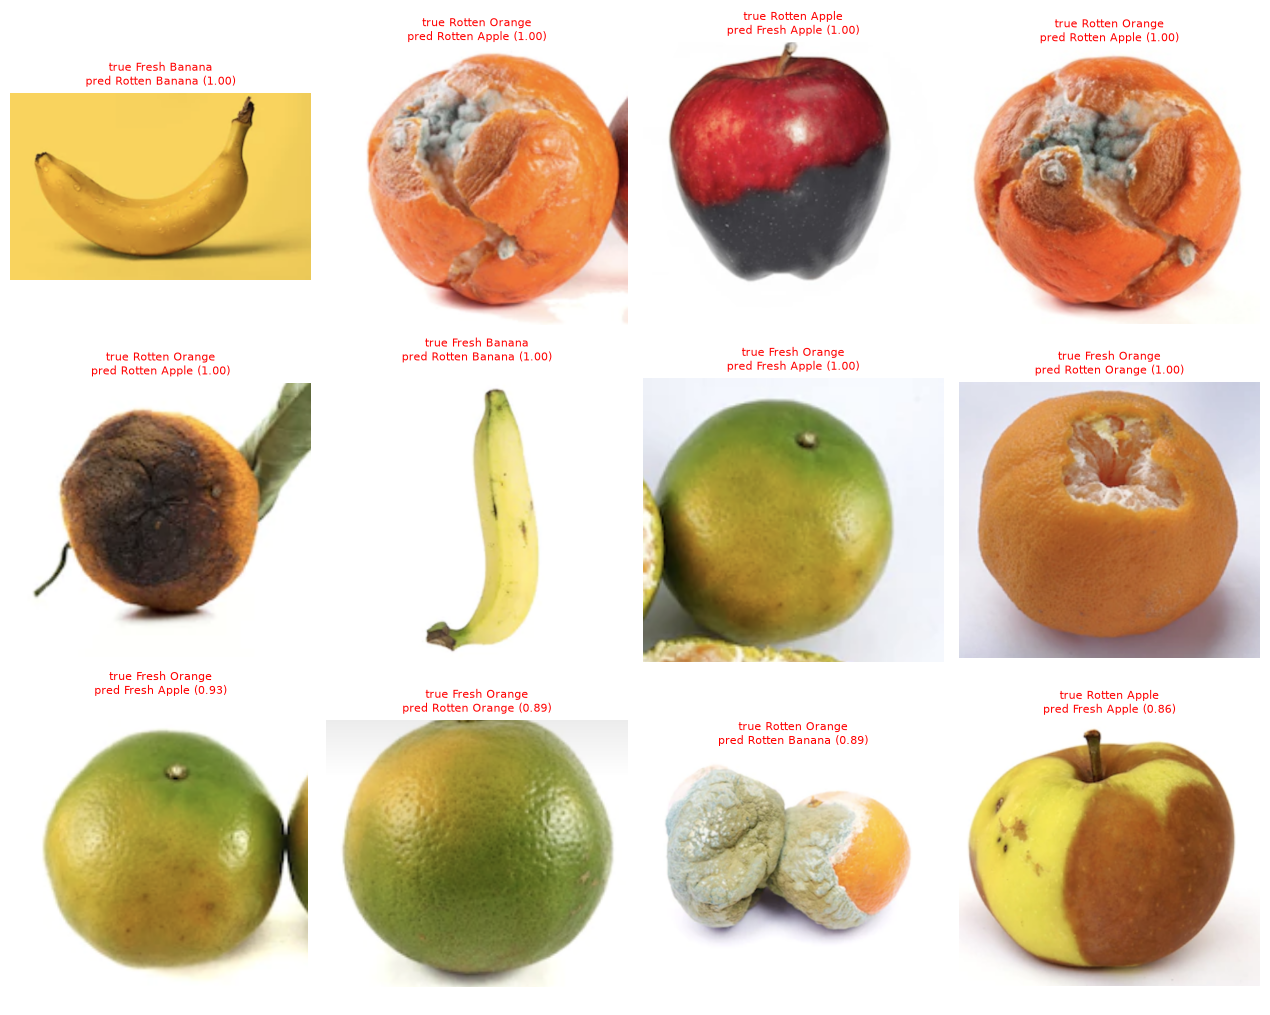

In [5]:
fig = EA.misclassified_gallery(pred, DATA_ROOT, n=12)
if fig is not None: plt.show()
else: print("No mistakes on this view.")

## 2. Grad-CAM - is the model looking at the fruit?

E0000 00:00:1792934666.721634  191806 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
I0000 00:00:1792934666.721670  191806 cuda_diagnostics.cc:160] env: CUDA_VISIBLE_DEVICES="-1"
I0000 00:00:1792934666.721685  191806 cuda_diagnostics.cc:163] CUDA_VISIBLE_DEVICES is set to -1 - this hides all GPUs from CUDA
I0000 00:00:1792934666.721692  191806 cuda_diagnostics.cc:171] verbose logging is disabled. Rerun with verbose logging (usually --v=1 or --vmodule=cuda_diagnostics=1) to get more diagnostic output from this module
I0000 00:00:1792934666.721693  191806 cuda_diagnostics.cc:176] retrieving CUDA diagnostic information for host: 725c64a7ed92
I0000 00:00:1792934666.721698  191806 cuda_diagnostics.cc:183] hostname: 725c64a7ed92
I0000 00:00:1792934666.721790  191806 cuda_diagnostics.cc:190] libcuda reported version is: 575.57.8
I0000 00:00:1792934666.721808  191806 cuda_diagnostics.cc:194] kern

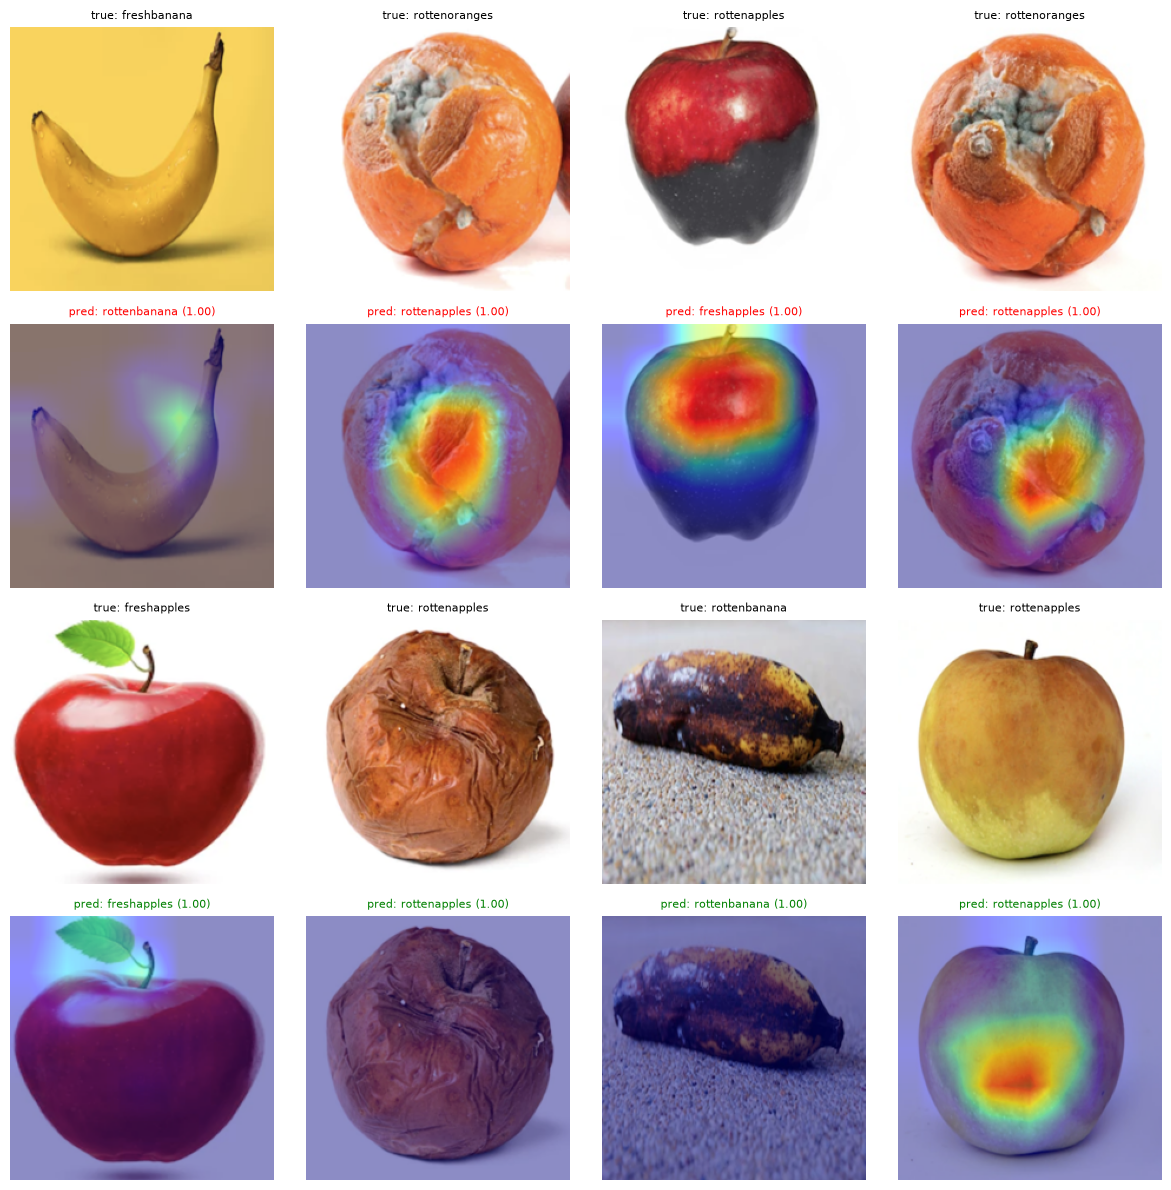

In [6]:
from tensorflow import keras
from fruitfresh.gradcam import plot_gradcam_grid
model = keras.models.load_model(run_dir_for(WORK_DIR, RUN, SEED) / "model.keras")
size = tuple(model.input_shape[1:3])
errs = EA.error_table(pred).head(4)
ok = pred[pred.y_true == pred.y_pred].sample(min(4, int((pred.y_true == pred.y_pred).sum())), random_state=0)
items = [(r["image_path"], config.CLASS_NAMES.index(r["true class"])) for r in errs.to_dict("records")] + [(r.image_path, int(r.y_true)) for r in ok.itertuples()]
imgs = [np.array(Image.open(DATA_ROOT / p).convert("RGB").resize(size)) for p, _ in items]
plot_gradcam_grid(model, imgs, [t for _, t in items]); plt.show()

## 3. The inference pipeline (what the app uses)

In [7]:
from fruitfresh.predict import FruitPredictor
predictor = FruitPredictor(resolve_model("auto", WORK_DIR, RESULTS, SEED))
for p in pred.image_path.head(3):
    r = predictor.predict(Image.open(DATA_ROOT / p))
    print(p.split("/")[-2], "->", r["label"], "|", r["status"].upper(), f"| confidence {r['confidence']:.1%}", "| uncertain" if r["uncertain"] else "")

freshapples -> Fresh Apple | FRESH | confidence 99.1% 
freshapples -> Fresh Apple | FRESH | confidence 100.0% 
freshapples -> Fresh Apple | FRESH | confidence 99.9% 


## 4. Real-world photos (optional but recommended)
Put your own phone photos in `real_world/<class_name>/*.jpg`, e.g. `real_world/rottenbanana/photo1.jpg`
(class names: freshapples, freshbanana, freshoranges, rottenapples, rottenbanana, rottenoranges). Never train on them.

In [8]:
REAL = PROJECT_DIR / "real_world"
rows = []
if REAL.exists():
    for cls_dir in sorted(p for p in REAL.iterdir() if p.is_dir() and p.name in config.CLASS_NAMES):
        for f in sorted(cls_dir.iterdir()):
            if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}:
                r = predictor.predict(Image.open(f)); rows.append({"file": f.name, "true": cls_dir.name, "pred": r["class_name"], "confidence": r["confidence"]})
if rows:
    rw = pd.DataFrame(rows); print("real-world accuracy:", round((rw.true == rw.pred).mean(), 3), "on", len(rw), "photos"); display(rw)
else:
    print("No real-world photos found in", REAL, "- skip this step or add some.")

No real-world photos found in /home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/real_world - skip this step or add some.


## 5. Export to TensorFlow Lite (optional)

In [9]:
from fruitfresh.export import export_tflite, validate_tflite
tflite = export_tflite(run_dir_for(WORK_DIR, RUN, SEED) / "model.keras", RESULTS / "export" / f"{RUN}.tflite", "dynamic")
sample = np.stack([np.array(Image.open(DATA_ROOT / p).convert("RGB").resize(size)) for p in pred.image_path.head(8)]).astype("float32")
print(json.dumps(validate_tflite(run_dir_for(WORK_DIR, RUN, SEED) / "model.keras", tflite, sample), indent=2))

INFO:tensorflow:Assets written to: /tmp/tmp0bbyk4n6/assets


INFO:tensorflow:Assets written to: /tmp/tmp0bbyk4n6/assets


Saved artifact at '/tmp/tmp0bbyk4n6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  124388230193872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230192528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230189264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230193296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230189456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230188688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230186384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230189648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230188112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230190224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124388230191376: Tens

W0000 00:00:1792934785.413648  191806 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792934785.413667  191806 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792934785.414035  191806 reader.cc:83] Reading SavedModel from: /tmp/tmp0bbyk4n6
I0000 00:00:1792934785.420513  191806 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1792934785.420521  191806 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0bbyk4n6
I0000 00:00:1792934785.494277  191806 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1792934785.509312  191806 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1792934786.001388  191806 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp0bbyk4n6
I0000 00:00:1792934786.102421  191806 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 688396 microseconds.
I0000 00:00:1792934786.208546  19180

{
  "n_images": 8,
  "max_abs_prob_diff": 0.0017804503440856934,
  "top1_agreement": 1.0,
  "keras_mb": 23.03,
  "tflite_mb": 2.53
}


/home/jovyan/work/onkar1/fresh-rotten-fruit-capstone/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 6. Launch the application
Set `LAUNCH_APP = True`. In Colab a public link is created (`share=True`); on a laptop open http://127.0.0.1:7860.
The same app from a terminal: `python app/app.py`.  Stop the cell (square button) to close it.

In [12]:
LAUNCH_APP = True
if LAUNCH_APP:
    sys.path.insert(0, str(PROJECT_DIR / "app"))
    from app import build_demo
    build_demo(resolve_model("auto", WORK_DIR, RESULTS, SEED)).launch(share=True, inline=IN_COLAB)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://7950e93802eec18ba7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
